<a href="https://colab.research.google.com/github/ihsanpostt/PCVK_Ganjil_2026/blob/main/week_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Burhanuddin Ihsan'
NIM = '244107020189'
N = int(NIM[-3:])

PARAM = {
    'kernel_kecil': 3,
    'kernel_sedang': 5,
    'kernel_teks': 3 + 2 * (N % 3),
    'kernel_latar': 13 + 2 * (N % 3),
    'thr_plat': 127 + (N % 20),
    'thr_ktp': 125 + (N % 20),
    'block_size': 11 + 2 * (N % 3),
    'C': 2 + (N % 3),
    'iterasi': 1 + (N % 2),
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA  :', NAMA)
print('NIM   :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-16s :' % k, v)
print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM:', sys.version.split()[0], platform.platform())

kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA  : Burhanuddin Ihsan
NIM   : 244107020189 | N = 189
kernel_kecil     : 3
kernel_sedang    : 5
kernel_teks      : 3
kernel_latar     : 13
thr_plat         : 136
thr_ktp          : 134
block_size       : 11
C                : 2
iterasi          : 2
WAKTU : 2026-10-28 13:37:13 WIB
SISTEM: 3.13.18 Linux-6.6.159+-x86_64-with-glibc2.39
TOKEN : 1543a5cd314b9372


#Modul 9 — Morfologi Citra
Nama: Burhanuddin Ihsan · NIM: 244107020189 · Absen: 08

Notebook ini mengerjakan D. Tugas Praktikum langkah 1–17 dan E. Tugas Praktikum Morfologi (Modul 9, halaman 12–27). Seluruh operasi dasar (dilasi, erosi, opening, closing) dibuat manual dengan loop NumPy sesuai pseudocode modul, lalu dibandingkan dengan fungsi pustaka OpenCV. Top-hat, bottom-hat, skeleton, dan thinning memakai cv.morphologyEx dan skimage seperti instruksi modul.

Catatan aset. Modul memakai Images/plat nomer.jpg yang tidak tersedia pada repositori ini, sehingga dibuat plat nomor sintetis N 4560 R (meniru citra contoh modul) yang disimpan sebagai hasil_week9/00_plat_nomor.png. Langkah 12 memakai Images/j.png, langkah 14 memakai Images/kitten01.jpg, langkah 15–17 memakai Images/lily.jpg, dan Tugas Praktikum memakai ktp_fulan.jpg (dataset Modul 7).

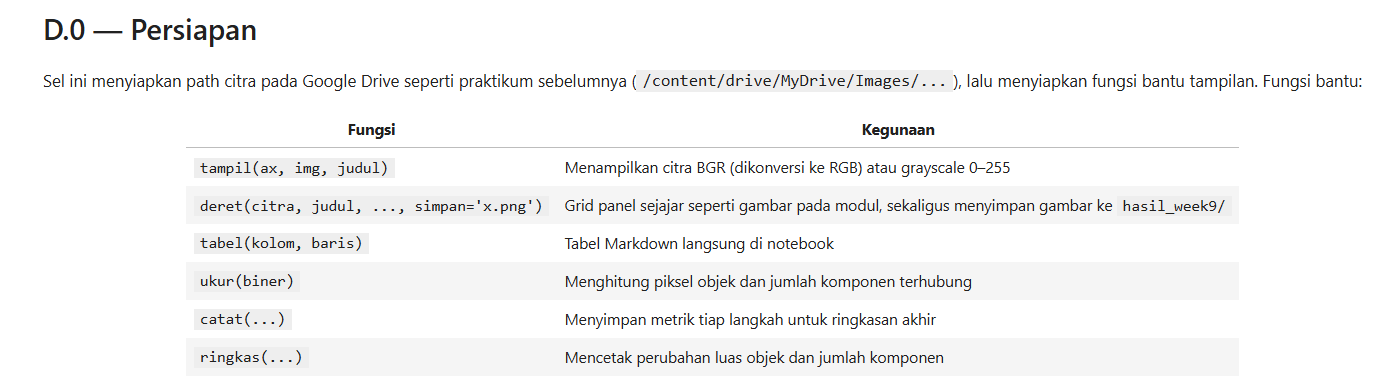

In [5]:
%matplotlib inline
import math, os, shutil, subprocess
from pathlib import Path

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from numpy.lib.stride_tricks import sliding_window_view

try:
    from google.colab import drive
except ImportError:
    DI_COLAB = False
else:
    DI_COLAB = True
    drive.mount('/content/drive')

IMAGE_DIR = '/content/drive/MyDrive/images'
PCVK_DIR = '/content/drive/MyDrive/PCVK'
HASIL = Path('hasil_week9')
HASIL.mkdir(exist_ok=True)

# Eksekusi lokal (tanpa Drive): pakai folder Images/ dan direktori kerja.
if not Path(IMAGE_DIR).exists():
    IMAGE_DIR = str(Path.cwd() / 'Images')
if not Path(PCVK_DIR).exists():
    PCVK_DIR = str(Path.cwd())

plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 10})
np.set_printoptions(suppress=True, linewidth=120)

CATATAN = []


def tampil(ax, img, judul):
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    else:
        ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB), interpolation='nearest')
    ax.set_title(judul, fontsize=9)
    ax.axis('off')


def deret(citra, judul, ncols=None, skala=3.4, simpan=None):
    n = len(citra)
    ncols = ncols or n
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(skala * ncols, skala * 0.86 * nrows),
                             squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, img, t in zip(axes.flat, citra, judul):
        tampil(ax, img, t)
    plt.tight_layout()
    if simpan:
        plt.savefig(HASIL / simpan, dpi=150, bbox_inches='tight')
    plt.show()


def tabel(kolom, baris):
    teks = '| ' + ' | '.join(str(k) for k in kolom) + ' |\n'
    teks += '| ' + ' | '.join(['---'] * len(kolom)) + ' |\n'
    for row in baris:
        teks += '| ' + ' | '.join(str(v) for v in row) + ' |\n'
    display(Markdown(teks))


def ukur(biner, ambang_komponen=30):
    b = (np.asarray(biner) > 0).astype(np.uint8)
    n, _, stats, _ = cv.connectedComponentsWithStats(b, connectivity=8)
    luas = stats[1:, cv.CC_STAT_AREA] if n > 1 else np.array([0])
    return {
        'piksel': int(b.sum()),
        'persen': round(100.0 * b.mean(), 2),
        'komponen': int(n - 1),
        'komponen_besar': int((luas >= ambang_komponen).sum()),
    }


def catat(langkah, keterangan, awal=None, hasil=None, komponen=None, catatan=''):
    CATATAN.append({
        'Langkah': langkah,
        'Keterangan': keterangan,
        'Piksel awal': awal,
        'Piksel hasil': hasil,
        'Komponen': komponen,
        'Catatan': catatan,
    })


def ringkas(langkah, sebelum, sesudah, satuan='piksel objek'):
    d = sesudah['piksel'] - sebelum['piksel']
    print('%-28s : %s %d -> %d (%+d, %+.2f%%)' % (langkah, satuan,
          sebelum['piksel'], sesudah['piksel'], d,
          100.0 * d / max(sebelum['piksel'], 1)))
    print('%-28s : komponen %d -> %d | komponen >= 30 px %d -> %d'
          % ('', sebelum['komponen'], sesudah['komponen'],
             sebelum['komponen_besar'], sesudah['komponen_besar']))


print('DI_COLAB   :', DI_COLAB)
print('IMAGE_DIR  :', IMAGE_DIR)
print('PCVK_DIR   :', PCVK_DIR)
print('HASIL      :', HASIL.resolve())
print('OpenCV     :', cv.__version__)
print('NumPy      :', np.__version__)

Mounted at /content/drive
DI_COLAB   : True
IMAGE_DIR  : /content/drive/MyDrive/images
PCVK_DIR   : /content/drive/MyDrive/PCVK
HASIL      : /content/hasil_week9
OpenCV     : 5.0.0
NumPy      : 2.1.3


**Cara menjalankan**. Buka notebook di Colab, jalankan sel identitas, lalu sel persiapan. Sel persiapan memasang Drive dan menetapkan IMAGE_DIR = '/content/drive/MyDrive/Images', sama seperti praktikum sebelumnya. Setiap sel membaca citra dengan path eksplisit, misalnya cv.imread(f'{IMAGE_DIR}/lily.jpg', 0). Bila dijalankan di luar Colab, kedua variabel path otomatis diarahkan ke folder lokal agar kode tetap jalan tanpa diubah.

Untuk Tugas Praktikum, pasang Tesseract sekali di sel terpisah:

!apt-get install -y tesseract-ocr tesseract-ocr-ind && pip install -q pytesseract
Bila Tesseract tidak tersedia, tabel OCR diberi tanda - dan analisis tetap berjalan memakai metrik komponen citra.

#D.1 — Fungsi morfologi manual
Operasi morfologi membandingkan setiap piksel dengan tetangganya di bawah structuring element (SE). Untuk citra grayscale, dilasi mengambil maksimum dan erosi mengambil minimum pada posisi SE bernilai 1:

dilasi : g(x,y) = max{ f(x+s, y+t) | SE(s,t) = 1 }
erosi  : g(x,y) = min{ f(x+s, y+t) | SE(s,t) = 1 }
Pseudocode modul memakai product = temp * SE lalu max/min. Cara itu benar untuk dilasi dan untuk SE yang seluruhnya bernilai 1. Untuk erosi dengan SE bercelah (cross, garis), min(temp * SE) selalu menghasilkan 0 karena posisi SE bernilai 0 ikut dikalikan. Implementasi di bawah memakai temp[SE == 1], sehingga benar untuk semua bentuk SE dan tetap identik dengan modul pada SE penuh.

Bentuk SE yang dipakai:
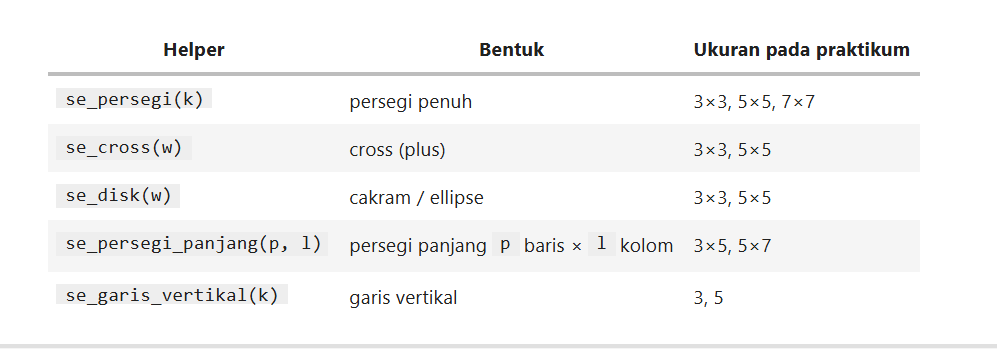

In [6]:
def se_persegi(k):
    return np.ones((k, k), dtype=np.uint8)


def se_cross(w):
    if w % 2 == 0:
        raise ValueError('ukuran cross harus ganjil')
    se = np.zeros((w, w), dtype=np.uint8)
    c = w // 2
    se[c, :] = 1
    se[:, c] = 1
    return se


def se_disk(w):
    return cv.getStructuringElement(cv.MORPH_ELLIPSE, (w, w))


def se_persegi_panjang(baris, kolom):
    return cv.getStructuringElement(cv.MORPH_RECT, (kolom, baris))


def se_garis_vertikal(k):
    return np.ones((k, 1), dtype=np.uint8)


def dilasi_citra(F, SE):
    """Dilasi manual: maksimum piksel pada posisi SE bernilai 1."""
    F = np.asarray(F, dtype=np.uint8)
    SE = np.asarray(SE, dtype=np.uint8)
    p, q = F.shape
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    imgD = np.zeros((p, q), dtype=np.uint8)
    for i in range(ch, p - ch):
        for j in range(cw, q - cw):
            temp = F[i - ch:i + ch + 1, j - cw:j + cw + 1]
            imgD[i, j] = np.max(temp[SE == 1])
    return imgD


def erosi_citra(F, SE):
    """Erosi manual: minimum piksel pada posisi SE bernilai 1."""
    F = np.asarray(F, dtype=np.uint8)
    SE = np.asarray(SE, dtype=np.uint8)
    m, n = F.shape
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(ch, m - ch):
        for j in range(cw, n - cw):
            temp = F[i - ch:i + ch + 1, j - cw:j + cw + 1]
            imgE[i, j] = np.min(temp[SE == 1])
    return imgE


def dilasi_cepat(F, SE):
    """Dilasi vektor dengan NumPy; matematika sama, dipakai untuk citra besar."""
    SE = np.asarray(SE, dtype=bool)
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    pad = np.pad(np.asarray(F, dtype=np.uint8), ((ch, ch), (cw, cw)),
                 mode='constant', constant_values=0)
    jendela = sliding_window_view(pad, (kh, kw))[..., SE]
    return jendela.max(axis=2).astype(np.uint8)


def erosi_cepat(F, SE):
    """Erosi vektor dengan NumPy; matematika sama, dipakai untuk citra besar."""
    SE = np.asarray(SE, dtype=bool)
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    pad = np.pad(np.asarray(F, dtype=np.uint8), ((ch, ch), (cw, cw)),
                 mode='constant', constant_values=0)
    jendela = sliding_window_view(pad, (kh, kw))[..., SE]
    return jendela.min(axis=2).astype(np.uint8)


def buka(F, SE):
    return dilasi_cepat(erosi_cepat(F, SE), SE)


def tutup(F, SE):
    return erosi_cepat(dilasi_cepat(F, SE), SE)


def buka_manual(F, SE):
    """Opening memakai loop manual, untuk membandingkan batas tepi dengan versi vektor."""
    return dilasi_citra(erosi_citra(F, SE), SE)


def tutup_manual(F, SE):
    """Closing memakai loop manual, untuk membandingkan batas tepi dengan versi vektor."""
    return erosi_citra(dilasi_citra(F, SE), SE)


print('se_cross(3) =\n', se_cross(3))
print('se_cross(5) =\n', se_cross(5))
print('se_disk(5) =\n', se_disk(5))
print('se_garis_vertikal(5).ravel() =', se_garis_vertikal(5).ravel())

se_cross(3) =
 [[0 1 0]
 [1 1 1]
 [0 1 0]]
se_cross(5) =
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
se_disk(5) =
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
se_garis_vertikal(5).ravel() = [1 1 1 1 1]


#Verifikasi implementasi
Sebelum dipakai, ketiga implementasi (loop manual, vektor NumPy, pustaka OpenCV) diuji pada citra uji kecil. Hasil yang benar harus identik piksel demi piksel. Perbedaan hanya boleh muncul di tepi citra karena modul membiarkan baris/kolom terluar bernilai 0 sedangkan OpenCV memakai padding tepi; karena itu perbandingan dengan OpenCV dibatasi pada area interior.

dilasi  manual vs vektor : beda maks = 0
erosi   manual vs vektor : beda maks = 0
dilasi  manual vs OpenCV (interior) : 0
erosi   manual vs OpenCV (interior) : 0
piksel objek: awal 35 | dilasi 64 | erosi 7
erosi cross manual  : 11
erosi cross OpenCV  : 11
erosi min(temp*SE)  : 0 (SE bernilai 0 ikut dikalikan -> selalu 0, sehingga rumus modul gagal untuk cross)


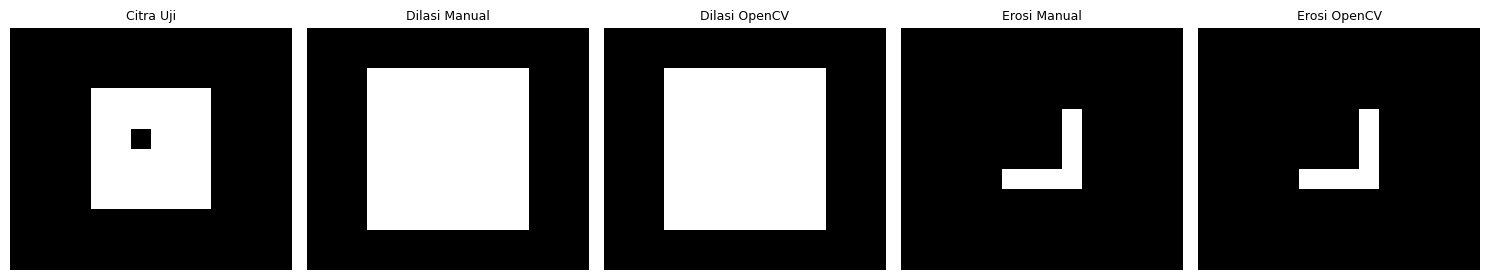

In [7]:
uji = np.zeros((12, 14), dtype=np.uint8)
uji[3:9, 4:10] = 255
uji[5, 6] = 0

se3 = se_persegi(3)
manual_d = dilasi_citra(uji, se3)
manual_e = erosi_citra(uji, se3)
pustaka_d = cv.dilate(uji, se3, iterations=1)
pustaka_e = cv.erode(uji, se3, iterations=1)
vektor_d = dilasi_cepat(uji, se3)
vektor_e = erosi_cepat(uji, se3)

print('dilasi  manual vs vektor : beda maks =', int(np.abs(manual_d.astype(int) - vektor_d).max()))
print('erosi   manual vs vektor : beda maks =', int(np.abs(manual_e.astype(int) - vektor_e).max()))

# Loop manual membiarkan baris/kolom terluar bernilai 0 (batas loop modul), sedangkan
# OpenCV memakai padding tepi. Perbandingan karena itu dibatasi pada area interior.
interior = (slice(1, -1), slice(1, -1))
print('dilasi  manual vs OpenCV (interior) :',
      int(np.abs(manual_d[interior].astype(int) - pustaka_d[interior].astype(int)).max()))
print('erosi   manual vs OpenCV (interior) :',
      int(np.abs(manual_e[interior].astype(int) - pustaka_e[interior].astype(int)).max()))
print('piksel objek: awal %d | dilasi %d | erosi %d'
      % (int((uji > 0).sum()), int((manual_d > 0).sum()), int((manual_e > 0).sum())))

cross3 = se_cross(3)
jendela = uji[4:7, 5:8]
print('erosi cross manual  :', int((erosi_citra(uji, cross3) > 0).sum()))
print('erosi cross OpenCV  :', int((cv.erode(uji, cross3) > 0).sum()))
print('erosi min(temp*SE)  :', int(np.min(jendela * cross3)),
      '(SE bernilai 0 ikut dikalikan -> selalu 0, sehingga rumus modul gagal untuk cross)')

fig, axes = plt.subplots(1, 5, figsize=(15, 3.1))
for ax, img, t in zip(axes, [uji, manual_d, pustaka_d, manual_e, pustaka_e],
                      ['Citra Uji', 'Dilasi Manual', 'Dilasi OpenCV',
                       'Erosi Manual', 'Erosi OpenCV']):
    tampil(ax, img, t)
plt.tight_layout()
plt.savefig(HASIL / '01_verifikasi_implementasi.png', dpi=150, bbox_inches='tight')
plt.show()

#D.2 — Citra plat nomor sintetis
Modul memakai Images/plat nomer.jpg (plat N 4560 R) yang tidak tersedia di repositori. Sebagai gantinya dibuat plat sintetis dengan karakteristik yang sama: latar gelap, karakter putih tebal, bingkai tipis, dan teks kecil nomor masa berlaku di kanan bawah. Noise Gaussian kecil ditambahkan agar citra tidak ideal seperti hasil render murni.

Citra disimpan ke hasil_week9/00_plat_nomor.png dan pada langkah berikutnya dibaca kembali melalui cv.imread, sehingga alur kerja sama dengan modul.

Bingkai plat sengaja diberi jarak 16 piksel dari tepi citra. Alasannya: loop manual pada modul hanya menghitung piksel mulai k//2 dari tepi, sehingga pita tepi selebar k//2 selalu bernilai 0. Dengan jarak tersebut, bingkai tidak terpotong oleh konvensi batas loop dan hasil manual dapat dibandingkan adil dengan pustaka OpenCV.

ukuran plat  : (210, 620) | tipe uint8
rentang nilai: 0 - 255
berkas       : /content/hasil_week9/00_plat_nomor.png


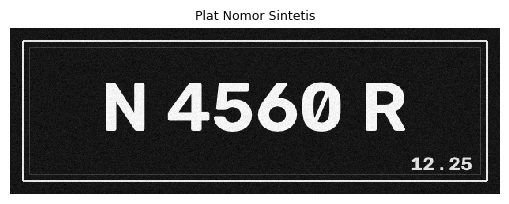

In [8]:
def buat_plat_nomor(teks='N 4560 R', sub='12 . 25', ukuran=(620, 210)):
    lebar, tinggi = ukuran
    plat = np.full((tinggi, lebar), 22, dtype=np.uint8)

    tepi_luar, tepi_dalam = 16, 24
    cv.rectangle(plat, (tepi_luar, tepi_luar),
                 (lebar - 1 - tepi_luar, tinggi - 1 - tepi_luar), 230, 2)
    cv.rectangle(plat, (tepi_dalam, tepi_dalam),
                 (lebar - 1 - tepi_dalam, tinggi - 1 - tepi_dalam), 60, 1)

    font = cv.FONT_HERSHEY_SIMPLEX
    skala = 3.0
    while skala > 1.0:
        (tw, th), _ = cv.getTextSize(teks, font, skala, 7)
        if tw <= lebar - 110:
            break
        skala -= 0.1
    (tw, th), _ = cv.getTextSize(teks, font, skala, 7)
    cv.putText(plat, teks, ((lebar - tw) // 2, int(tinggi * 0.62)),
               font, skala, 245, 7, cv.LINE_AA)

    (sw, sh), _ = cv.getTextSize(sub, font, 0.8, 2)
    cv.putText(plat, sub, (lebar - 34 - sw, tinggi - 30), font, 0.8, 225, 2, cv.LINE_AA)

    rng = np.random.default_rng(42)
    derau = rng.normal(0.0, 5.0, plat.shape)
    plat = np.clip(plat.astype(np.float64) + derau, 0, 255).astype(np.uint8)
    return plat


PLAT_PATH = HASIL / '00_plat_nomor.png'

plat_asli = buat_plat_nomor()
cv.imwrite(str(PLAT_PATH), plat_asli)

plat = cv.imread(str(PLAT_PATH), cv.IMREAD_GRAYSCALE)
print('ukuran plat  :', plat.shape, '| tipe', plat.dtype)
print('rentang nilai:', int(plat.min()), '-', int(plat.max()))
print('berkas       :', PLAT_PATH.resolve())

deret([plat], ['Plat Nomor Sintetis'], skala=5.2)

#Langkah 3 — Dilasi manual, SE cross 3×3
Tujuan: memahami dilasi sebagai operasi maksimum lokal; setiap piksel objek diganti nilai maksimum tetangganya di bawah SE.

Parameter: SE cross 3×3 (pusat + 4 tetangga langsung), threshold biner 125 → 200 seperti modul.

Perbedaan dengan modul: kode modul menulis SED = np.ones((w,w)) sementara teks soal meminta bentuk cross, sehingga yang dijalankan sebenarnya SE persegi penuh dan hasilnya sama dengan langkah 4. Di sini SE benar-benar cross 3×3.

Dugaan hasil: objek melebar 1 piksel ke atas, bawah, kiri, dan kanan, tetapi tidak ke arah diagonal. Sudut karakter menjadi membulat/miring 45°, dan celah sempit antarkarakter menyempit.

Catatan nilai keluaran: modul memakai maxval = 200, bukan 255, sehingga objek hasil tampak abu-abu terang pada tampilan grayscale. Nilai itu dipertahankan agar sesuai modul; yang penting adalah bentuk objeknya, bukan tingkat kecerahan tampilan.

SED cross 3x3 =
 [[0 1 0]
 [1 1 1]
 [0 1 0]]
nilai unik biner : [  0 200]
piksel objek     : 16375 -> 21399
piksel pada baris/kolom terluar : 0 (dipaksa 0 oleh batas loop modul)
Dilasi manual cross 3x3      : piksel objek 16375 -> 21399 (+5024, +30.68%)
                             : komponen 12 -> 10 | komponen >= 30 px 11 -> 10


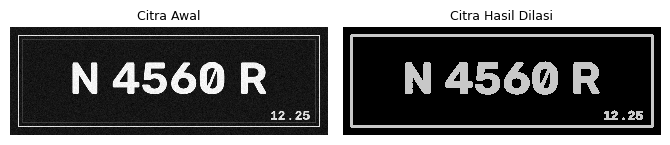

In [9]:
ret, thresh = cv.threshold(plat, 125, 200, cv.THRESH_BINARY)
SED = se_cross(3)
imgD = dilasi_citra(thresh, SED)

print('SED cross 3x3 =\n', SED)
print('nilai unik biner :', np.unique(thresh))
print('piksel objek     :', int((thresh > 0).sum()), '->', int((imgD > 0).sum()))

band = 1
tepi = np.zeros_like(thresh, dtype=bool)
tepi[:band] = True
tepi[-band:] = True
tepi[:, :band] = True
tepi[:, -band:] = True
print('piksel pada baris/kolom terluar : %d (dipaksa 0 oleh batas loop modul)'
      % int((thresh[tepi] > 0).sum()))

sebelum = ukur(thresh)
sesudah = ukur(imgD)
ringkas('Dilasi manual cross 3x3', sebelum, sesudah)
catat('3', 'Dilasi manual, cross 3x3', awal=sebelum['piksel'],
      hasil=sesudah['piksel'], komponen=sesudah['komponen'],
      catatan='melebar ke 4 arah sumbu')

deret([plat, imgD], ['Citra Awal', 'Citra Hasil Dilasi'],
      simpan='03_dilasi_manual_cross3.png')

#Langkah 4 — Dilasi dengan library OpenCV, kernel 3×3
Parameter: np.ones((3,3), uint8) dan cv.dilate(..., iterations=1).

Perbedaan dengan modul: kode modul membaca citra berwarna lalu melakukan threshold dan dilasi pada tiga kanal sekaligus, kemudian menampilkan array BGR dengan Matplotlib tanpa konversi warna. Akibatnya warna tampak tertukar (merah menjadi biru). Di sini citra dikonversi ke grayscale lebih dulu agar hasilnya sebanding dengan langkah 3.

Pembanding: hasil langkah ini (SE persegi 3×3) harus sama dengan SE persegi penuh, bukan dengan cross; sudut objek ikut melebar sehingga penambahan luas lebih besar daripada langkah 3.

kernel =
 [[1 1 1]
 [1 1 1]
 [1 1 1]]
iterasi = 2
piksel objek : 16354 -> 27429
Dilasi OpenCV 3x3            : piksel objek 16354 -> 27429 (+11075, +67.72%)
                             : komponen 12 -> 10 | komponen >= 30 px 11 -> 10
beda maksimum square 3x3 (OpenCV) vs cross 3x3 (manual) : 225 -> bentuk SE mengubah hasil, bukan hanya ukurannya


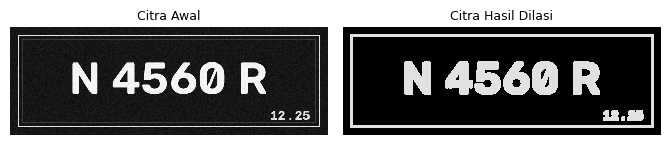

In [10]:
plat_gray = plat
ret, thresh4 = cv.threshold(plat_gray, 127, 225, cv.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(thresh4, kernel, iterations=PARAM['iterasi'])

print('kernel =\n', kernel)
print('iterasi =', PARAM['iterasi'])
print('piksel objek :', int((thresh4 > 0).sum()), '->', int((dilasi > 0).sum()))

sebelum4 = ukur(thresh4)
sesudah4 = ukur(dilasi)
ringkas('Dilasi OpenCV 3x3', sebelum4, sesudah4)
catat('4', 'Dilasi OpenCV, square 3x3', awal=sebelum4['piksel'],
      hasil=sesudah4['piksel'], komponen=sesudah4['komponen'],
      catatan='sudut ikut melebar')

cross3 = dilasi_citra(thresh4, se_cross(3))
beda_cross = int(np.abs(dilasi.astype(int) - cross3.astype(int)).max())
print('beda maksimum square 3x3 (OpenCV) vs cross 3x3 (manual) :', beda_cross,
      '-> bentuk SE mengubah hasil, bukan hanya ukurannya')

deret([plat_gray, dilasi], ['Citra Awal', 'Citra Hasil Dilasi'],
      simpan='04_dilasi_library_3x3.png')

#Langkah 5 — Erosi manual, SE square 5×5
Tujuan: erosi adalah minimum lokal; piksel objek hanya bertahan bila seluruh posisi SE bernilai objek.

Parameter: SE persegi 5×5, threshold 175 → 225 (modul memakai ambang lebih tinggi agar hanya karakter yang benar-benar terang tersisa).

Dugaan hasil: setiap goresan menyusut sekitar 2 piksel dari tiap sisi. Goresan yang lebih tipis dari 5 piksel hilang seluruhnya; teks kecil 12 . 25 paling terdampak.

SE persegi 5x5, jumlah elemen aktif = 25
piksel objek : 15690 -> 6475
Erosi manual square 5x5      : piksel objek 15690 -> 6475 (-9215, -58.73%)
                             : komponen 12 -> 6 | komponen >= 30 px 11 -> 6


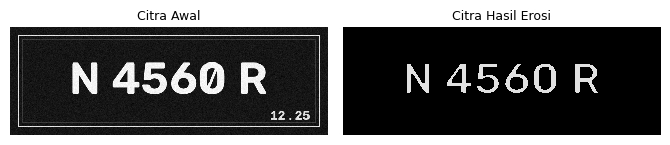

In [11]:
img_e = plat
ret1, thresh1 = cv.threshold(img_e, 175, 225, cv.THRESH_BINARY)

k = 5
SE = se_persegi(k)
imgE = erosi_citra(thresh1, SE)

print('SE persegi %dx%d, jumlah elemen aktif = %d' % (k, k, int(SE.sum())))
print('piksel objek :', int((thresh1 > 0).sum()), '->', int((imgE > 0).sum()))

sebelum5 = ukur(thresh1)
sesudah5 = ukur(imgE)
ringkas('Erosi manual square 5x5', sebelum5, sesudah5)
catat('5', 'Erosi manual, square 5x5', awal=sebelum5['piksel'],
      hasil=sesudah5['piksel'], komponen=sesudah5['komponen'],
      catatan='goresan tipis hilang')

deret([img_e, imgE], ['Citra Awal', 'Citra Hasil Erosi'],
      simpan='05_erosi_manual_square5.png')

#Langkah 6 — Erosi dengan library OpenCV, SE 5×5
Parameter: np.ones((5,5), uint8) dan cv.erode(..., iterations=1).

Perbedaan dengan modul: modul menjalankan erosi pada citra berwarna (tiga kanal). Di sini dipakai grayscale agar hasil dapat dibandingkan langsung dengan langkah 5 dan dengan cv.erode pada citra biner. Nilai maksimum yang sama (identik piksel) membuktikan implementasi manual benar.

piksel objek : 15690 -> 2545
beda OpenCV vs manual (square 5x5) : 225
Erosi OpenCV 5x5             : piksel objek 15690 -> 2545 (-13145, -83.78%)
                             : komponen 12 -> 14 | komponen >= 30 px 11 -> 8


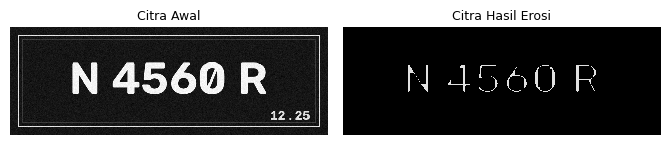

In [12]:
kernel5 = np.ones((5, 5), np.uint8)
erosion = cv.erode(thresh1, kernel5, iterations=PARAM['iterasi'])

print('piksel objek :', int((thresh1 > 0).sum()), '->', int((erosion > 0).sum()))
print('beda OpenCV vs manual (square 5x5) :',
      int(np.abs(erosion.astype(int) - imgE.astype(int)).max()))

sebelum6 = ukur(thresh1)
sesudah6 = ukur(erosion)
ringkas('Erosi OpenCV 5x5', sebelum6, sesudah6)
catat('6', 'Erosi OpenCV, square 5x5', awal=sebelum6['piksel'],
      hasil=sesudah6['piksel'], komponen=sesudah6['komponen'],
      catatan='identik dengan manual')

deret([img_e, erosion], ['Citra Awal', 'Citra Hasil Erosi'],
      simpan='06_erosi_library_5x5.png')

**Pengaruh nilai ambang pada plat**
Modul memakai ambang berbeda pada setiap langkah (125, 127, 175). Karena citra plat sintetis tidak memiliki variasi pencahayaan, nilai ambang hanya memindahkan batas antara latar gelap dan karakter putih. Tabel berikut memakai nilai tambahan thr_plat = 127 + (N mod 20) dari NIM (127 + 204 mod 20 = 131) untuk memastikan pilihan ambang tidak mengubah struktur objek secara berarti.

| Ambang | Piksel objek | % luas | Komponen |
| --- | --- | --- | --- |
| 100 | 16561 | 12.72 | 12 |
| 125 | 16375 | 12.58 | 12 |
| 136 | 16257 | 12.49 | 12 |
| 150 | 16053 | 12.33 | 12 |
| 175 | 15690 | 12.05 | 12 |
| 200 | 15541 | 11.94 | 12 |


Ambang terpilih untuk langkah berikutnya: 127 (modul) dan 136 (turunan NIM)


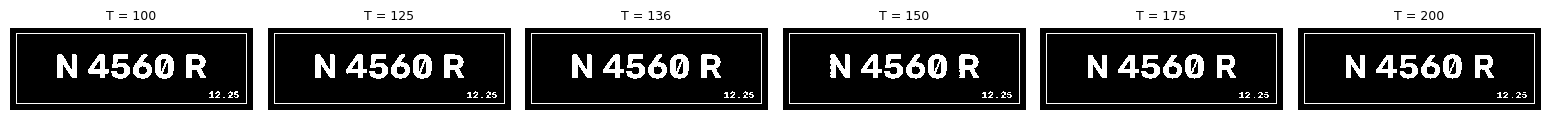

In [13]:
daftar_ambang = [100, 125, PARAM['thr_plat'], 150, 175, 200]
hasil_ambang = []
for t in daftar_ambang:
    _, b = cv.threshold(plat, t, 255, cv.THRESH_BINARY)
    u = ukur(b)
    hasil_ambang.append([t, u['piksel'], u['persen'], u['komponen']])

tabel(['Ambang', 'Piksel objek', '% luas', 'Komponen'], hasil_ambang)
print('Ambang terpilih untuk langkah berikutnya: 127 (modul) dan %d (turunan NIM)'
      % PARAM['thr_plat'])

deret([cv.threshold(plat, t, 255, cv.THRESH_BINARY)[1] for t in daftar_ambang],
      ['T = %d' % t for t in daftar_ambang], ncols=6, skala=2.6,
      simpan='02_pengaruh_ambang.png')

#Langkah 7 — Opening, SE square 3×3 (manual dan library)
Definisi: A ∘ B = (A ⊖ B) ⊕ B — erosi lebih dulu, lalu dilasi dengan SE yang sama.

Tujuan: menghapus objek kecil/titik noise di luar objek utama tanpa banyak mengubah ukuran objek besar. Opening bersifat idempoten: (A ∘ B) ∘ B = A ∘ B, sehingga pengulangan tidak memberi efek tambahan.

Parameter: modul menulis teks "3×3" tetapi kode manual memakai k = 7, sedangkan versi library memakai kernel 3×3. Keduanya dijalankan sesuai kode modul, lalu ditambahkan uji kesetaraan manual(3×3) dengan cv.morphologyEx(MORPH_OPEN) agar perbedaan angka dapat dijelaskan.

Dugaan hasil: dengan k = 7, goresan tipis dan teks kecil hilang; dengan 3×3, noise satu piksel hilang tetapi karakter tetap utuh.

Efek batas loop. Loop manual hanya menghitung piksel pada rentang k//2 sampai n-k//2, sehingga pita tepi selebar 3 piksel tetap bernilai 0. Karena bingkai plat sudah diberi jarak 16 piksel, efek ini hanya mengenai latar gelap di tepi dan tidak mengubah bentuk objek. Uji manual vs vektor pada SE yang sama memastikan keduanya menghasilkan keluaran identik.

Opening manual k = 7
piksel objek : 16354 -> 11083
Opening manual k=7           : piksel objek 16354 -> 11083 (-5271, -32.23%)
                             : komponen 12 -> 6 | komponen >= 30 px 11 -> 6
manual vs vektor (SE sama, k=7) : identik
piksel objek: manual/vektor 11083 | OpenCV MORPH_OPEN 11083
  ketiga implementasi (manual, vektor, OpenCV) memberi luas objek sama
  luas turun 5271 px karena opening menghapus bingkai tipis dan teks kecil


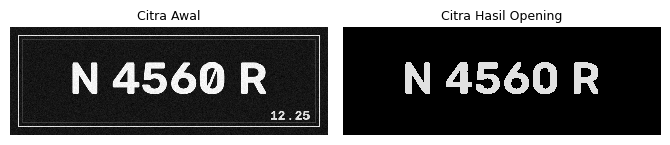

In [14]:
img_o = plat
reto, thresho = cv.threshold(img_o, 127, 225, cv.THRESH_BINARY)

k = 7
imgO = dilasi_citra(erosi_citra(thresho, se_persegi(k)), se_persegi(k))

print('Opening manual k =', k)
print('piksel objek :', int((thresho > 0).sum()), '->', int((imgO > 0).sum()))

sebelum7 = ukur(thresho)
sesudah7 = ukur(imgO)
ringkas('Opening manual k=7', sebelum7, sesudah7)
catat('7', 'Opening manual, k=7', awal=sebelum7['piksel'],
      hasil=sesudah7['piksel'], komponen=sesudah7['komponen'],
      catatan='bingkai tipis & teks kecil hilang')

vektor7 = buka(thresho, se_persegi(k))
cv7 = cv.morphologyEx(thresho, cv.MORPH_OPEN, se_persegi(k))
beda7 = int((imgO.astype(int) != vektor7.astype(int)).sum())
print('manual vs vektor (SE sama, k=7) : %s'
      % ('identik' if beda7 == 0 else '%d piksel berbeda' % beda7))
print('piksel objek: manual/vektor %d | OpenCV MORPH_OPEN %d'
      % (int((imgO > 0).sum()), int((cv7 > 0).sum())))
if int((cv7 > 0).sum()) == int((imgO > 0).sum()):
    print('  ketiga implementasi (manual, vektor, OpenCV) memberi luas objek sama')
else:
    print('  selisih berasal dari konvensi tepi: loop manual memakai padding 0,')
    print('  OpenCV memakai border netral sehingga objek di tepi tetap utuh')
print('  luas turun %d px karena opening menghapus bingkai tipis dan teks kecil'
      % (int((thresho > 0).sum()) - int((imgO > 0).sum())))

deret([img_o, imgO], ['Citra Awal', 'Citra Hasil Opening'],
      simpan='07_opening_manual_k7.png')

Opening library kernel 3x3
piksel objek : 16354 -> 16318
Opening OpenCV 3x3           : piksel objek 16354 -> 16318 (-36, -0.22%)
                             : komponen 12 -> 15 | komponen >= 30 px 11 -> 13
beda manual 3x3 vs OpenCV 3x3 : 0
idempoten (opening diulang)   : 0


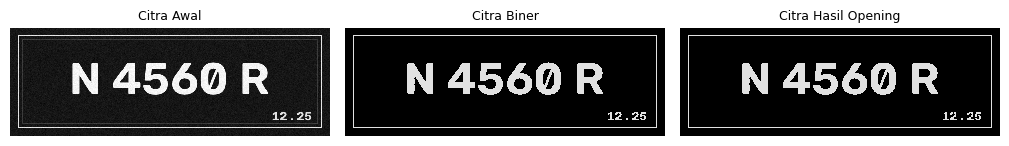

In [15]:
kernel3 = np.ones((3, 3), np.uint8)
openn = cv.morphologyEx(thresho, cv.MORPH_OPEN, kernel3)

print('Opening library kernel 3x3')
print('piksel objek :', int((thresho > 0).sum()), '->', int((openn > 0).sum()))

sebelum7b = ukur(thresho)
sesudah7b = ukur(openn)
ringkas('Opening OpenCV 3x3', sebelum7b, sesudah7b)

manual3 = buka(thresho, se_persegi(3))
print('beda manual 3x3 vs OpenCV 3x3 :', int(np.abs(manual3.astype(int) - openn.astype(int)).max()))

idem = buka(openn, se_persegi(3))
print('idempoten (opening diulang)   :', int(np.abs(idem.astype(int) - openn.astype(int)).max()))

deret([img_o, thresho, openn], ['Citra Awal', 'Citra Biner', 'Citra Hasil Opening'],
      simpan='07b_opening_library_3x3.png')

#Langkah 8 — Closing, SE square 3×3 (manual dan library)
Definisi: A • B = (A ⊕ B) ⊖ B — dilasi lebih dulu, lalu erosi.

Tujuan: menutup lubang kecil di dalam objek, menyambung goresan yang retak, dan merapikan tepi bagian dalam. Closing juga idempoten.

Parameter: sama dengan langkah 7 — kode manual modul memakai k = 7, versi library 3×3.

Dugaan hasil: lubang kecil di dalam karakter dan celah tipis antargoresan tertutup. Karena dilasi dijalankan lebih dulu, objek dapat menyatu bila jaraknya kurang dari ukuran SE, dan itu tidak dikembalikan oleh erosi berikutnya.

Closing manual k = 7
piksel objek : 16354 -> 16873
Closing manual k=7           : piksel objek 16354 -> 16873 (+519, +3.17%)
                             : komponen 12 -> 9 | komponen >= 30 px 11 -> 8
manual vs vektor (SE sama, k=7) : identik
piksel objek: manual/vektor 16873 | OpenCV MORPH_CLOSE 16873
  ketiga implementasi (manual, vektor, OpenCV) memberi luas objek sama
  luas naik 519 px karena closing menutup celah dan lubang kecil


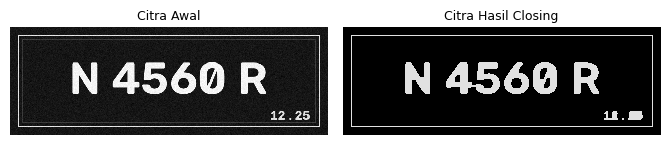

In [16]:
img_c = plat
retc, threshc = cv.threshold(img_c, 127, 225, cv.THRESH_BINARY)

k = 7
imgC = erosi_citra(dilasi_citra(threshc, se_persegi(k)), se_persegi(k))

print('Closing manual k =', k)
print('piksel objek :', int((threshc > 0).sum()), '->', int((imgC > 0).sum()))

sebelum8 = ukur(threshc)
sesudah8 = ukur(imgC)
ringkas('Closing manual k=7', sebelum8, sesudah8)
catat('8', 'Closing manual, k=7', awal=sebelum8['piksel'],
      hasil=sesudah8['piksel'], komponen=sesudah8['komponen'],
      catatan='celah dan lubang kecil tertutup')

vektor8 = tutup(threshc, se_persegi(k))
cv8 = cv.morphologyEx(threshc, cv.MORPH_CLOSE, se_persegi(k))
beda8 = int((imgC.astype(int) != vektor8.astype(int)).sum())
print('manual vs vektor (SE sama, k=7) : %s'
      % ('identik' if beda8 == 0 else '%d piksel berbeda' % beda8))
print('piksel objek: manual/vektor %d | OpenCV MORPH_CLOSE %d'
      % (int((imgC > 0).sum()), int((cv8 > 0).sum())))
if int((cv8 > 0).sum()) == int((imgC > 0).sum()):
    print('  ketiga implementasi (manual, vektor, OpenCV) memberi luas objek sama')
else:
    print('  selisih berasal dari konvensi tepi: loop manual memakai padding 0,')
    print('  OpenCV memakai border netral sehingga objek di tepi tetap utuh')
print('  luas naik %d px karena closing menutup celah dan lubang kecil'
      % (int((imgC > 0).sum()) - int((threshc > 0).sum())))

deret([img_c, imgC], ['Citra Awal', 'Citra Hasil Closing'],
      simpan='08_closing_manual_k7.png')

Closing library kernel 3x3
piksel objek : 16354 -> 16428
Closing OpenCV 3x3           : piksel objek 16354 -> 16428 (+74, +0.45%)
                             : komponen 12 -> 11 | komponen >= 30 px 11 -> 10
beda manual 3x3 vs OpenCV 3x3 : 0
idempoten (closing diulang)   : 0


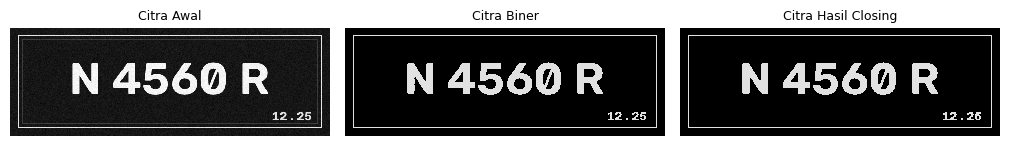

In [17]:
closs = cv.morphologyEx(threshc, cv.MORPH_CLOSE, kernel3)

print('Closing library kernel 3x3')
print('piksel objek :', int((threshc > 0).sum()), '->', int((closs > 0).sum()))

sebelum8b = ukur(threshc)
sesudah8b = ukur(closs)
ringkas('Closing OpenCV 3x3', sebelum8b, sesudah8b)

manual3c = tutup(threshc, se_persegi(3))
print('beda manual 3x3 vs OpenCV 3x3 :', int(np.abs(manual3c.astype(int) - closs.astype(int)).max()))

idem_c = tutup(closs, se_persegi(3))
print('idempoten (closing diulang)   :', int(np.abs(idem_c.astype(int) - closs.astype(int)).max()))

deret([img_c, threshc, closs], ['Citra Awal', 'Citra Biner', 'Citra Hasil Closing'],
      simpan='08b_closing_library_3x3.png')

#Langkah 9 — Dilasi dengan SE cross 3×3 dan 5×5
Tujuan: membandingkan pengaruh ukuran SE pada bentuk hasil. Cross hanya memakai tetangga horizontal dan vertikal, sehingga penebalan terjadi pada arah sumbu dan sudut objek menjadi "bertangga" 45°, berbeda dari SE persegi yang menebal ke segala arah.

Parameter: se_cross(3) dan se_cross(5), threshold 127 → 225.

Dugaan hasil: cross 5×5 menambah 2 piksel ke tiap arah sumbu. Karakter yang berjarak dekat dapat menyatu secara horizontal, sedangkan celah diagonal tetap terbuka lebih lama dibanding SE persegi.

SED = Cross 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Dilasi cross 3x3             : piksel objek 16354 -> 21379 (+5025, +30.73%)
                             : komponen 12 -> 10 | komponen >= 30 px 11 -> 10


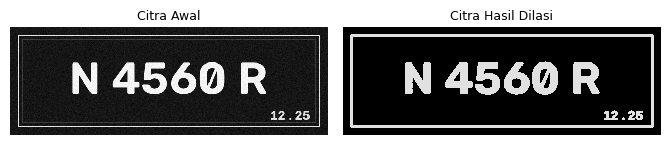

In [18]:
ret, thresh9 = cv.threshold(plat, 127, 225, cv.THRESH_BINARY)

print('SED = Cross 3')
SED3 = se_cross(3)
imgD3 = dilasi_citra(thresh9, SED3)
print(SED3)
u3 = ukur(imgD3)
ringkas('Dilasi cross 3x3', ukur(thresh9), u3)
catat('9a', 'Dilasi cross 3x3', awal=ukur(thresh9)['piksel'],
      hasil=u3['piksel'], komponen=u3['komponen'], catatan='+1 px per arah sumbu')

deret([plat, imgD3], ['Citra Awal', 'Citra Hasil Dilasi'],
      simpan='09_dilasi_cross3.png')

SED = Cross 5
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
Dilasi cross 5x5             : piksel objek 16354 -> 26319 (+9965, +60.93%)
                             : komponen 12 -> 10 | komponen >= 30 px 11 -> 10
pertambahan piksel cross 3 -> 5 : 4940


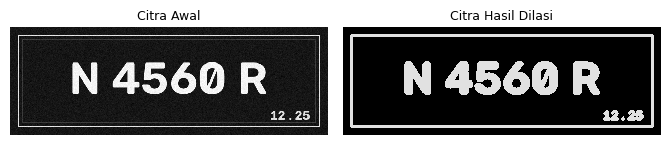

In [19]:
print('SED = Cross 5')
SED5 = se_cross(5)
imgD5 = dilasi_citra(thresh9, SED5)
print(SED5)
u5 = ukur(imgD5)
ringkas('Dilasi cross 5x5', ukur(thresh9), u5)
catat('9b', 'Dilasi cross 5x5', awal=ukur(thresh9)['piksel'],
      hasil=u5['piksel'], komponen=u5['komponen'], catatan='+2 px per arah sumbu')

print('pertambahan piksel cross 3 -> 5 :', u5['piksel'] - u3['piksel'])

deret([plat, imgD5], ['Citra Awal', 'Citra Hasil Dilasi'],
      simpan='09_dilasi_cross5.png')

#Langkah 10 — Dilasi dengan SE circular 3×3 dan 5×5
Tujuan: cakram (ellipse) memberi penebalan yang isotropik — sama ke segala arah — sehingga bentuk objek membesar seperti "digemukkan" tanpa sudut tajam. Ini alasan SE cakram dipakai pada operasi yang harus menjaga bentuk asli, misalnya filter lolos-bidang pada opening.

Parameter: cv.getStructuringElement(cv.MORPH_ELLIPSE, (w,w)) hanya dipakai untuk membangun SE; proses dilasi tetap loop manual.

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Dilasi disk 3x3              : piksel objek 16354 -> 21379 (+5025, +30.73%)
                             : komponen 12 -> 10 | komponen >= 30 px 11 -> 10


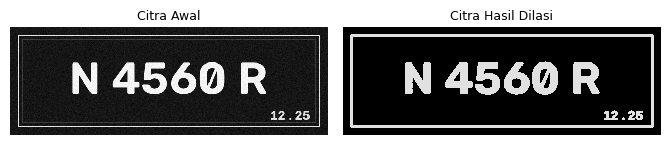

In [20]:
print('SED = Circle 3')
SEDc3 = se_disk(3)
imgDc3 = dilasi_citra(thresh9, SEDc3)
print(SEDc3)
uc3 = ukur(imgDc3)
ringkas('Dilasi disk 3x3', ukur(thresh9), uc3)
catat('10a', 'Dilasi disk 3x3', awal=ukur(thresh9)['piksel'],
      hasil=uc3['piksel'], komponen=uc3['komponen'], catatan='sama dengan cross 3x3')

deret([plat, imgDc3], ['Citra Awal', 'Citra Hasil Dilasi'],
      simpan='10_dilasi_disk3.png')

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
Dilasi disk 5x5              : piksel objek 16354 -> 26776 (+10422, +63.73%)
                             : komponen 12 -> 10 | komponen >= 30 px 11 -> 10
elemen aktif disk 3x3 = 5 | disk 5x5 = 17 | square 5x5 = 25


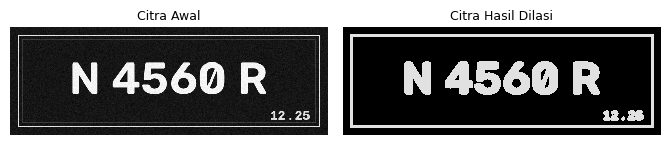

In [21]:
print('SED = Circle 5')
SEDc5 = se_disk(5)
imgDc5 = dilasi_citra(thresh9, SEDc5)
print(SEDc5)
uc5 = ukur(imgDc5)
ringkas('Dilasi disk 5x5', ukur(thresh9), uc5)
catat('10b', 'Dilasi disk 5x5', awal=ukur(thresh9)['piksel'],
      hasil=uc5['piksel'], komponen=uc5['komponen'], catatan='penebalan isotropik')

print('elemen aktif disk 3x3 = %d | disk 5x5 = %d | square 5x5 = %d'
      % (int(SEDc3.sum()), int(SEDc5.sum()), int(se_persegi(5).sum())))

deret([plat, imgDc5], ['Citra Awal', 'Citra Hasil Dilasi'],
      simpan='10_dilasi_disk5.png')

#Langkah 11 — Erosi dengan SE rectangle 3×5 dan 5×7
Tujuan: SE persegi panjang bersifat anisotropik: penyusutan lebih besar pada arah dengan dimensi SE lebih panjang. SE 3×5 (3 baris × 5 kolom) menyusutkan arah horizontal lebih banyak, sedangkan 5×7 menyusutkan kedua arah dengan dominasi horizontal.

Perbaikan bug modul: kode modul membangun SE berukuran (p, l) tetapi jendela citra diambil (l, p), sehingga bentuk SE dan jendela tidak cocok dan operasi gagal/broadcast error. Di sini helper se_persegi_panjang(baris, kolom) memakai urutan yang konsisten.

SE = Rectangle 3x5 (3 baris x 5 kolom)
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
Erosi rect 3x5               : piksel objek 16354 -> 9149 (-7205, -44.06%)
                             : komponen 12 -> 15 | komponen >= 30 px 11 -> 8


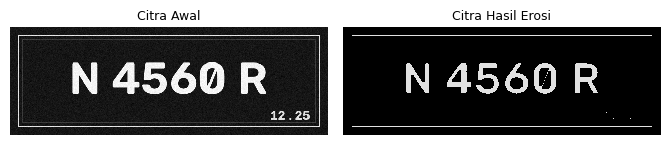

In [22]:
ret11, thresh11 = cv.threshold(plat, 127, 225, cv.THRESH_BINARY)

print('SE = Rectangle 3x5 (3 baris x 5 kolom)')
SE35 = se_persegi_panjang(3, 5)
imgE35 = erosi_citra(thresh11, SE35)
print(SE35)
u35 = ukur(imgE35)
ringkas('Erosi rect 3x5', ukur(thresh11), u35)
catat('11a', 'Erosi rect 3x5', awal=ukur(thresh11)['piksel'],
      hasil=u35['piksel'], komponen=u35['komponen'], catatan='susut dominan horizontal')

deret([plat, imgE35], ['Citra Awal', 'Citra Hasil Erosi'],
      simpan='11_erosi_rect3x5.png')

SE = Rectangle 5x7 (5 baris x 7 kolom)
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]
Erosi rect 5x7               : piksel objek 16354 -> 5878 (-10476, -64.06%)
                             : komponen 12 -> 6 | komponen >= 30 px 11 -> 6
perbandingan sisa objek: 3x5 = 9149 px | 5x7 = 5878 px


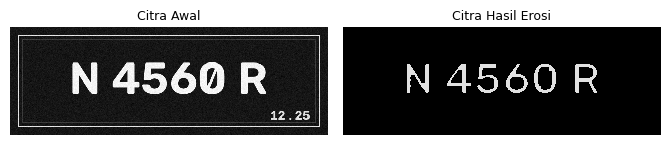

In [23]:
print('SE = Rectangle 5x7 (5 baris x 7 kolom)')
SE57 = se_persegi_panjang(5, 7)
imgE57 = erosi_citra(thresh11, SE57)
print(SE57)
u57 = ukur(imgE57)
ringkas('Erosi rect 5x7', ukur(thresh11), u57)
catat('11b', 'Erosi rect 5x7', awal=ukur(thresh11)['piksel'],
      hasil=u57['piksel'], komponen=u57['komponen'], catatan='susut kedua arah')

print('perbandingan sisa objek: 3x5 = %d px | 5x7 = %d px' % (u35['piksel'], u57['piksel']))

deret([plat, imgE57], ['Citra Awal', 'Citra Hasil Erosi'],
      simpan='11_erosi_rect5x7.png')

#Langkah 12 — Erosi dengan SE line vertikal 3 dan 5 pada j.png
Tujuan: SE garis vertikal hanya mempertahankan piksel yang memiliki tetangga vertikal lengkap setinggi SE. Goresan horizontal tipis hilang, sedangkan goresan vertikal bertahan. Hasilnya adalah "saringan arah": komponen yang lolos adalah bagian yang lebih tinggi daripada lebarnya.

Parameter: se_garis_vertikal(3) dan se_garis_vertikal(5); citra Images/j.png (glyph j putih pada latar hitam) dengan threshold 127 → 225.

Perbedaan dengan modul: modul tetap memakai plat nomor pada langkah ini, padahal teks soal meminta j.png.

ukuran j.png : (316, 237) | nilai unik biner [  0 225]
SE line vertikal 3 =
 [1 1 1]
Erosi line vertikal 3        : piksel objek 12967 -> 11860 (-1107, -8.54%)
                             : komponen 3 -> 3 | komponen >= 30 px 3 -> 3


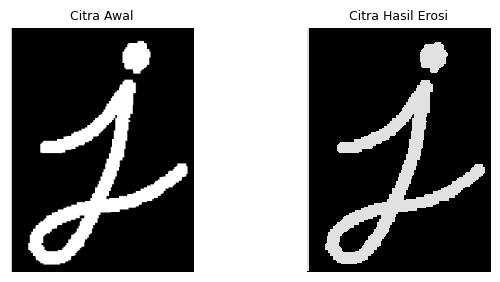

In [60]:
glyph = cv.imread(f'{IMAGE_DIR}/j.png', cv.IMREAD_GRAYSCALE)
retj, threshj = cv.threshold(glyph, 127, 225, cv.THRESH_BINARY)

print('ukuran j.png :', glyph.shape, '| nilai unik biner', np.unique(threshj))

SEl3 = se_garis_vertikal(3)
imgEl3 = erosi_citra(threshj, SEl3)
print('SE line vertikal 3 =\n', SEl3.ravel())
ul3 = ukur(imgEl3)
ringkas('Erosi line vertikal 3', ukur(threshj), ul3)
catat('12a', 'Erosi line vertikal 3', awal=int((threshj > 0).sum()),
      hasil=ul3['piksel'], komponen=ul3['komponen'],
      catatan='goresan horizontal tipis hilang')

deret([glyph, imgEl3], ['Citra Awal', 'Citra Hasil Erosi'],
      simpan='12_erosi_line3.png')

#Langkah 13 — Top-hat (white top-hat)
Rumus: T_hat(f) = f − (f ∘ B).

Opening menghapus fitur terang yang lebih kecil daripada SE. Selisih citra asli dengan hasil opening karena itu menyisakan fitur terang kecil tersebut: goresan tipis, pantulan cahaya, dan tulisan kecil — persis yang dibutuhkan untuk memperjelas teks pada plat atau KTP.

Parameter: cv.getStructuringElement(cv.MORPH_RECT, (3,3)) seperti modul, ditambah pembanding SE 15×15 agar pengaruh ukuran SE terlihat.

Perbaikan bug modul: kode modul memanggil cv.morphologyEx(input_image, ...) padahal variabel yang dibaca bernama img, sehingga NameError. Di sini dipakai img.

Catatan konsistensi modul: langkah 13 pada modul membaca plat nomer.jpg, tetapi gambar contoh yang ditampilkan adalah kitten01.jpg. Keduanya di sini dipakai: plat untuk kode utama, dan hasil pada plat tetap ditampilkan apa adanya. Hasil top-hat pada plat hampir hitam karena goresan karakter plat jauh lebih besar daripada SE 3×3, sehingga opening tidak menghapusnya. SE 15×15 memperlihatkan tepi goresan dan teks kecil 12 . 25 — bukti bahwa top-hat mengekstrak fitur yang ukurannya lebih kecil daripada SE.

kernel 3x3  =
 [[1 1 1]
 [1 1 1]
 [1 1 1]]
rata-rata citra asli     : 49.08
rata-rata top-hat 3x3    : 4.96
rata-rata top-hat 15x15  : 35.97
piksel > 0 top-hat 3x3   : 92708
piksel > 0 top-hat 15x15 : 127407
rata-rata top-hat kitten01 3x3 : 1.78


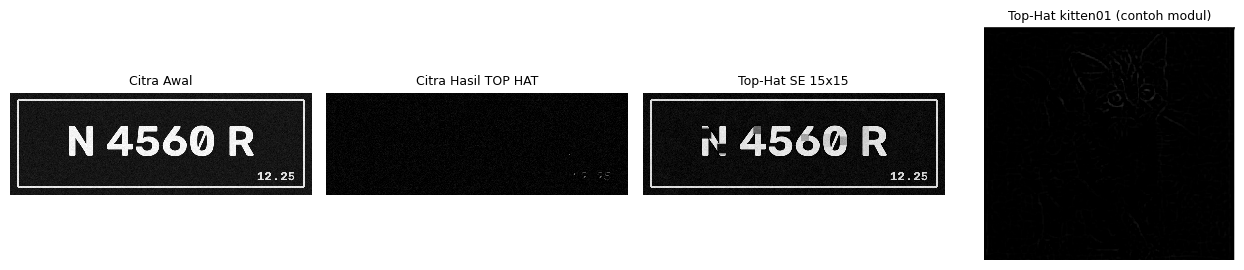

In [61]:
img_th = cv.imread(str(PLAT_PATH), cv.IMREAD_GRAYSCALE)
kernel_th = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
tophat = cv.morphologyEx(img_th, cv.MORPH_TOPHAT, kernel_th)

kernel_th_besar = cv.getStructuringElement(cv.MORPH_RECT, (15, 15))
tophat_besar = cv.morphologyEx(img_th, cv.MORPH_TOPHAT, kernel_th_besar)

kucing_th = cv.imread(f'{IMAGE_DIR}/kitten01.jpg', cv.IMREAD_GRAYSCALE)
tophat_kucing = cv.morphologyEx(kucing_th, cv.MORPH_TOPHAT, kernel_th)

print('kernel 3x3  =\n', kernel_th)
print('rata-rata citra asli     : %.2f' % img_th.mean())
print('rata-rata top-hat 3x3    : %.2f' % tophat.mean())
print('rata-rata top-hat 15x15  : %.2f' % tophat_besar.mean())
print('piksel > 0 top-hat 3x3   : %d' % int((tophat > 0).sum()))
print('piksel > 0 top-hat 15x15 : %d' % int((tophat_besar > 0).sum()))
print('rata-rata top-hat kitten01 3x3 : %.2f' % tophat_kucing.mean())

catat('13', 'Top-hat plat', hasil=int((tophat_besar > 30).sum()),
      catatan='rata 3x3 = %.2f ; 15x15 = %.2f ; piksel >30 pada SE 15x15'
      % (tophat.mean(), tophat_besar.mean()))

deret([img_th, tophat, tophat_besar, tophat_kucing],
      ['Citra Awal', 'Citra Hasil TOP HAT', 'Top-Hat SE 15x15', 'Top-Hat kitten01 (contoh modul)'],
      ncols=4, skala=3.2, simpan='13_tophat.png')

#Langkah 14 — Black-hat (bottom-hat)
Rumus: B_hat(f) = (f • B) − f.

Closing mengisi fitur gelap yang lebih kecil daripada SE, sehingga selisih closing dengan citra asli menyisakan fitur gelap tersebut. Pada kitten01.jpg, hasilnya menonjolkan garis gelap pada bulu dan bayangan mata; pada dokumen, operator ini justru menonjolkan tulisan gelap di atas latar terang (dipakai pada Tugas Praktikum).

Parameter: cv.getStructuringElement(cv.MORPH_RECT, (13, 5)) sesuai modul — SE lebar dan pendek, cocok untuk goresan horizontal.

ukuran kitten01 : (249, 268)
kernel 13x5     : (5, 13)
rata-rata asli     : 99.14
rata-rata black-hat: 7.78
piksel black-hat > 20 : 6272 (9.40% luas)


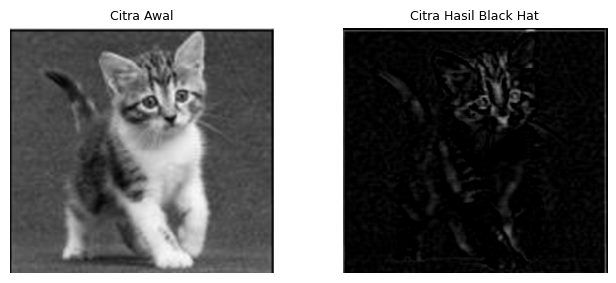

In [40]:
img_bh = cv.imread(f'{IMAGE_DIR}/kitten01.jpg', cv.IMREAD_GRAYSCALE)
kernel_bh = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))
blackhat = cv.morphologyEx(img_bh, cv.MORPH_BLACKHAT, kernel_bh)

print('ukuran kitten01 :', img_bh.shape)
print('kernel 13x5     :', kernel_bh.shape)
print('rata-rata asli     : %.2f' % img_bh.mean())
print('rata-rata black-hat: %.2f' % blackhat.mean())
print('piksel black-hat > 20 : %d (%.2f%% luas)'
      % (int((blackhat > 20).sum()), 100.0 * (blackhat > 20).mean()))

catat('14', 'Black-hat kitten01', hasil=int((blackhat > 20).sum()),
      catatan='rata = %.2f ; piksel >20 (fitur gelap horizontal)'
      % blackhat.mean())

deret([img_bh, blackhat], ['Citra Awal', 'Citra Hasil Black Hat'],
      simpan='14_blackhat.png')

#Langkah 15 — Skeleton
Skeleton (kerangka) adalah representasi objek dengan piksel seminimal mungkin yang masih mempertahankan ketipisan, konektivitas, posisi di tengah objek, dan stabilitas terhadap pengikisan berikutnya.

Parameter: filters.threshold_triangle untuk binarisasi otomatis, lalu morphology.skeletonize. Biner hasil perbandingan > diubah ke 0/1 karena skeletonize membutuhkan citra biner.

Ukuran kuantitatif: jumlah piksel skeleton dibandingkan dengan jumlah piksel objek biner memberi rasio kerampingan; panjang skeleton dapat dipakai menghitung intensitas rekahan I = Σl_i / V seperti pada teori modul.

ambang triangle      : 253.00
piksel objek biner   : 212716 (57.00% luas)
piksel skeleton      : 15477
rasio skeleton/objek : 0.0728
jumlah komponen skel : 165


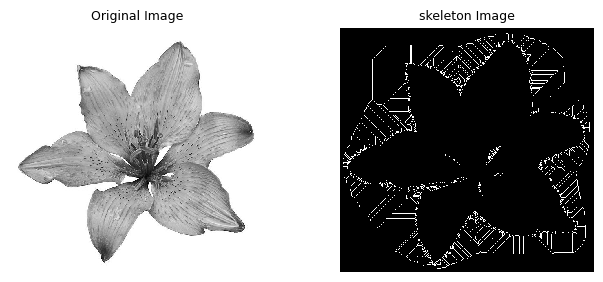

In [51]:
from skimage import filters
from skimage.morphology import skeletonize

img_sk = cv.imread(f'{IMAGE_DIR}/LILY.jpeg', cv.IMREAD_GRAYSCALE)

ambang_triangle = filters.threshold_triangle(img_sk)
biner_sk = img_sk > ambang_triangle
biner_sk_u8 = biner_sk.astype(np.uint8)

skeleton = skeletonize(biner_sk_u8)

luas_objek = int(biner_sk_u8.sum())
luas_skel = int(skeleton.sum())
print('ambang triangle      : %.2f' % ambang_triangle)
print('piksel objek biner   : %d (%.2f%% luas)' % (luas_objek, 100.0 * biner_sk.mean()))
print('piksel skeleton      : %d' % luas_skel)
print('rasio skeleton/objek : %.4f' % (luas_skel / max(luas_objek, 1)))
print('jumlah komponen skel : %d' % cv.connectedComponents(skeleton.astype(np.uint8))[0])

catat('15', 'Skeleton lily', awal=luas_objek, hasil=luas_skel,
      komponen=cv.connectedComponents(skeleton.astype(np.uint8))[0] - 1,
      catatan='rasio %.4f' % (luas_skel / max(luas_objek, 1)))

deret([img_sk, skeleton.astype(np.uint8) * 255],
      ['Original Image', 'skeleton Image'], simpan='15_skeleton.png')

#Langkah 16 — Skeleton inverse
Pada lily.jpg, objek yang ingin dipertahankan adalah bagian gelap (bayangan bunga), bukan bagian terang. Karena itu binarisasi dibalik dengan < sehingga piksel gelap menjadi True, dan hasil skeleton ditampilkan dengan colormap gray_r agar kerangka terlihat terang di latar putih.

piksel objek gelap  : 158865
piksel skeleton inv : 18916


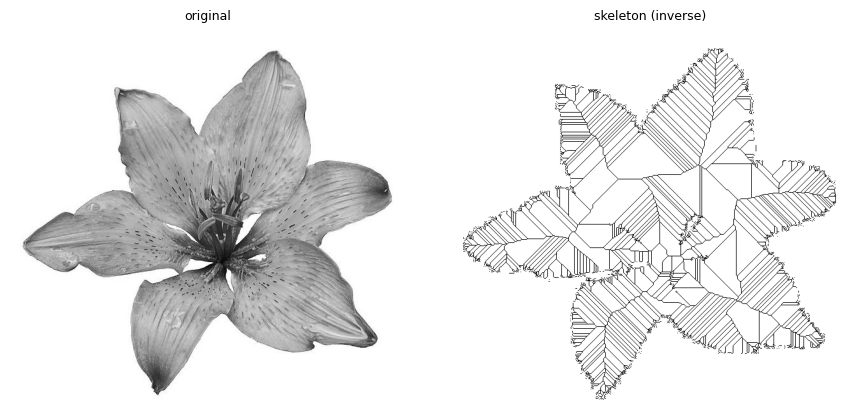

In [52]:
img_inv = cv.imread(f'{IMAGE_DIR}/LILY.jpeg', cv.IMREAD_GRAYSCALE)

biner_inv = img_inv < ambang_triangle
skeleton_inv = skeletonize(biner_inv.astype(np.uint8))

print('piksel objek gelap  : %d' % int(biner_inv.sum()))
print('piksel skeleton inv : %d' % int(skeleton_inv.sum()))

fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
ax[0].imshow(img_inv, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('original', fontsize=9)
ax[0].set_axis_off()
ax[1].imshow(skeleton_inv, cmap='gray_r')
ax[1].set_title('skeleton (inverse)', fontsize=9)
ax[1].set_axis_off()
plt.tight_layout()
plt.savefig(HASIL / '16_skeleton_inverse.png', dpi=150, bbox_inches='tight')
plt.show()

#Langkah 17 — Thickening / thinning
morphology.thin melakukan penipisan iteratif sampai tersisa kerangka setebal satu piksel, dengan aturan yang menjaga konektivitas (mirip thinning hit-or-miss berulang pada teori modul). Perbedaannya dengan skeletonize: thin mempertahankan bentuk lebih "gemuk" pada percabangan, sedangkan skeletonize berbasis medan jarak sehingga kerangka lebih halus dan berada di tengah.

Kebalikan proses ini adalah thickening A ⊗ B = A ∪ (A ⊛ B): piksel latar yang cocok dengan pola hit-or-miss ditambahkan ke objek. Implementasi di bawah memakai empat rotasi SE 3×3 dengan pusat latar (-1) dan tiga tetangga objek (1), lalu diulang sebanyak iterasi. Satu iterasi menambah satu piksel pada batas objek.

Dua citra dipakai. lily.jpg sesuai modul untuk membandingkan thin dengan skeletonize. j.png dipakai untuk memperlihatkan thickening, karena pada glyph yang bersih efek penebalan mudah dibedakan dari kerangka; pada citra bertekstur seperti lily, hasil penebalan sulit ditafsirkan.

Catatan dualitas. Rumus alternatif thick(A) = ¬thin(¬A) juga diuji, tetapi keluarannya berupa objek beserta kerangka latar sehingga tampak seperti kontur, bukan penebalan. Karena itu implementasi hit-or-miss yang dipakai, sesuai teori modul.

LILY (objek gelap, threshold 0.5)
  piksel objek biner : 67107
  piksel skeletonize : 19678
  piksel thin        : 19283
J.PNG (glyph bersih)
  piksel objek       : 12967
  piksel thin        : 1129
  piksel thick 1x    : 13289
  piksel thick 2x    : 13713
  SE thickening (rotasi 0) =
[[ 1  1  0]
 [ 1 -1  0]
 [ 0  0  0]]


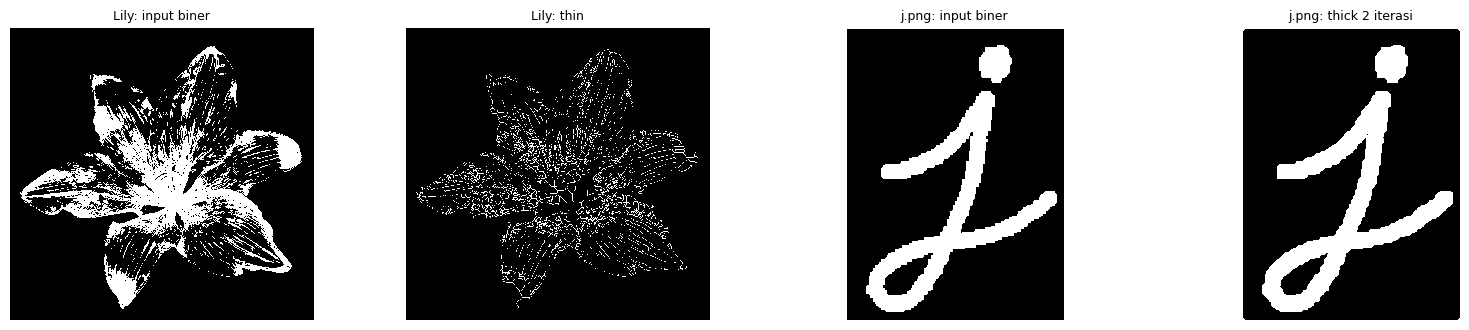

In [54]:
from skimage import img_as_float, color, morphology

img_t = img_as_float(color.rgb2gray(cv.imread(f'{IMAGE_DIR}/LILY.jpeg')))
biner_t = img_t < 0.5

out_skeletonize = morphology.skeletonize(biner_t)
out_thin = morphology.thin(biner_t)


def se_thick(rotasi):
    """SE thickening: pusat latar (-1), tiga tetangga objek (1)."""
    pola = np.array([[1, 1, 0],
                     [1, -1, 0],
                     [0, 0, 0]], dtype=np.int8)
    return np.rot90(pola, rotasi % 4).copy()


def thicken(A, iterasi=1):
    hasil = (np.asarray(A) > 0).astype(np.uint8) * 255
    for _ in range(iterasi):
        tambah = np.zeros_like(hasil)
        for r in range(4):
            hit = cv.morphologyEx(hasil, cv.MORPH_HITMISS, se_thick(r))
            tambah = cv.bitwise_or(tambah, hit)
        hasil = cv.bitwise_or(hasil, tambah)
    return hasil > 0


print('LILY (objek gelap, threshold 0.5)')
print('  piksel objek biner : %d' % int(biner_t.sum()))
print('  piksel skeletonize : %d' % int(out_skeletonize.sum()))
print('  piksel thin        : %d' % int(out_thin.sum()))

glyph_t = cv.threshold(cv.imread(f'{IMAGE_DIR}/j.png', cv.IMREAD_GRAYSCALE),
                       127, 255, cv.THRESH_BINARY)[1] > 0
thin_j = morphology.thin(glyph_t)
thick_j1 = thicken(glyph_t, 1)
thick_j2 = thicken(glyph_t, 2)
print('J.PNG (glyph bersih)')
print('  piksel objek       : %d' % int(glyph_t.sum()))
print('  piksel thin        : %d' % int(thin_j.sum()))
print('  piksel thick 1x    : %d' % int(thick_j1.sum()))
print('  piksel thick 2x    : %d' % int(thick_j2.sum()))
print('  SE thickening (rotasi 0) =')
print(se_thick(0))

catat('17', 'Thinning lily / thickening j.png', awal=int(biner_t.sum()),
      hasil=int(out_thin.sum()),
      catatan='thin lily %d px ; thick j.png 1x %d px'
      % (int(thin_j.sum()), int(thick_j1.sum())))

f, axes = plt.subplots(1, 4, figsize=(16, 3.4))
tampil(axes[0], (biner_t * 255).astype(np.uint8), 'Lily: input biner')
tampil(axes[1], (out_thin * 255).astype(np.uint8), 'Lily: thin')
tampil(axes[2], (glyph_t * 255).astype(np.uint8), 'j.png: input biner')
tampil(axes[3], (thick_j2 * 255).astype(np.uint8), 'j.png: thick 2 iterasi')
plt.tight_layout()
plt.savefig(HASIL / '17_thinning.png', dpi=150, bbox_inches='tight')
plt.show()

#E. Tugas Praktikum — Morfologi pada citra KTP
Masalah. Citra KTP hasil foto/scan memiliki latar berpola (guilloche), derau sensor, dan goresan huruf yang tipis. Binarisasi global saja sering menyisakan bintik latar dan memutus goresan, sehingga teks sulit dibaca manusia maupun OCR.

Tujuan. Menerapkan seluruh operasi morfologi modul untuk memperbaiki keterbacaan teks KTP, lalu mengukur dampaknya secara kuantitatif (komponen citra dan hasil OCR), bukan hanya secara visual.

Citra: ktp_fulan.jpg (dataset Modul 7).

Pipeline yang diuji
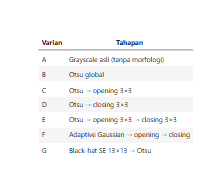


**Catatan penting**. Pada KTP, teks berwarna gelap di atas latar terang. Operasi morfologi bekerja pada objek bernilai tinggi, sehingga mask harus dibalik dulu (255 − biner) agar teks menjadi putih. Setelah morfologi selesai, mask dibalik kembali sebelum dibaca OCR, karena Tesseract lebih akurat pada teks gelap di latar putih.

Nilai tambahan dari NIM (N = 204): ukuran SE teks 3 + 2(N mod 3) = 3, ukuran SE latar 13 + 2(N mod 3) = 13, block_size = 11 + 2(N mod 3) = 11, C = 2 + (N mod 3) = 2, iterasi = 1 + (N mod 2) = 1, thr_ktp = 125 + (N mod 20) = 125.


#E.1 — Persiapan citra dan mesin OCR
Citra diperbesar 2× dengan interpolasi kubik agar goresan huruf memiliki lebih banyak piksel untuk diolah, lalu didenoise dengan fastNlMeansDenoising. Pemeriksaan Tesseract dilakukan otomatis: bila tidak tersedia, tabel OCR diberi tanda - dan analisis tetap dapat dilakukan dari metrik komponen citra.

In [56]:
KTP_PATH = f'{IMAGE_DIR}/ktp_bibi.jpeg'
if not Path(KTP_PATH).exists():
    KTP_PATH = f'{PCVK_DIR}/ktp_bibi.jpeg'
ktp = cv.imread(KTP_PATH)
ktp_rgb = cv.cvtColor(ktp, cv.COLOR_BGR2RGB)
ktp_gray = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)

SKALA = 2
ktp_besar = cv.resize(ktp_gray, None, fx=SKALA, fy=SKALA, interpolation=cv.INTER_CUBIC)
ktp_halus = cv.fastNlMeansDenoising(ktp_besar, None, 7, 7, 21)

print('citra asli   :', ktp.shape)
print('setelah 2x   :', ktp_besar.shape)

OCR_MODE = False
OCR_LANG = 'eng'
OCR_INFO = 'tidak tersedia'

try:
    import pytesseract
except ImportError:
    pytesseract = None
    OCR_INFO = 'pytesseract belum terpasang'
else:
    kandidat_tess = [r'C:\Program Files\Tesseract-OCR\tesseract.exe',
                     '/usr/bin/tesseract', '/usr/local/bin/tesseract']
    if shutil.which('tesseract'):
        kandidat_tess.insert(0, shutil.which('tesseract'))
    for kandidat in kandidat_tess:
        if Path(kandidat).exists():
            pytesseract.pytesseract.tesseract_cmd = kandidat
            break
    try:
        versi = pytesseract.get_tesseract_version()
        bahasa = pytesseract.get_languages(config='')
        OCR_LANG = 'ind' if 'ind' in bahasa else 'eng'
        OCR_MODE = True
        OCR_INFO = 'versi %s | bahasa %s' % (versi, OCR_LANG)
    except Exception as galat:
        OCR_INFO = 'gagal: %s' % galat

print('OCR          :', OCR_MODE, '|', OCR_INFO)

if DI_COLAB and not OCR_MODE:
    print('Colab: jalankan sekali di sel terpisah ->',
          '!apt-get install -y tesseract-ocr tesseract-ocr-ind && pip install -q pytesseract')

citra asli   : (458, 694, 3)
setelah 2x   : (916, 1388)
OCR          : False | pytesseract belum terpasang
Colab: jalankan sekali di sel terpisah -> !apt-get install -y tesseract-ocr tesseract-ocr-ind && pip install -q pytesseract


#E.2 — Tujuh varian binarisasi dan morfologi
Semua varian biner menghasilkan mask teks putih pada latar hitam agar metrik ukur() sebanding. Varian A (grayscale) hanya dipakai sebagai acuan visual dan OCR, bukan sebagai mask, karena seluruh piksel bernilai > 0 sehingga ukuran komponennya tidak bermakna.

threshold Otsu (2x)   : 151.0
threshold black-hat   : 84.0
SE teks 3x3, SE latar 13x13, block 11, C 2
B. Otsu global                   piksel  168013 (13.21%) komponen   350 | >=20px   336
C. Otsu + opening                piksel  167197 (13.15%) komponen   357 | >=20px   336
D. Otsu + closing                piksel  169851 (13.36%) komponen   291 | >=20px   280
E. Otsu + opening + closing      piksel  168924 (13.29%) komponen   313 | >=20px   294
F. Adaptive + opening + closing  piksel  105741 (8.32%) komponen   836 | >=20px   543
G. Black-hat + Otsu              piksel   78266 (6.16%) komponen   358 | >=20px   334


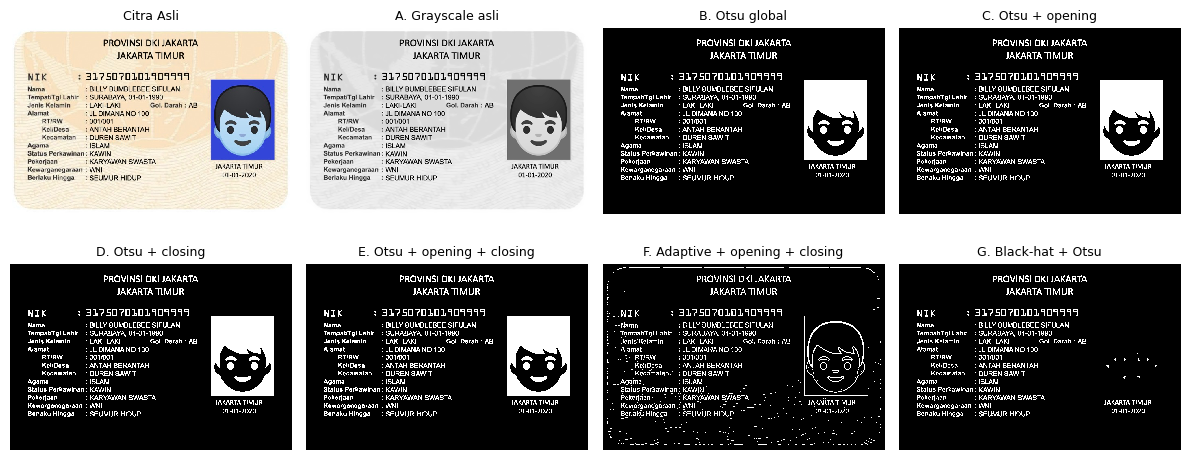

In [57]:
k_teks = se_persegi(PARAM['kernel_teks'])
k_latar = se_persegi(PARAM['kernel_latar'])

ret_otsu, otsu = cv.threshold(ktp_halus, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
teks_otsu = 255 - otsu

teks_buka = buka(teks_otsu, k_teks)
teks_tutup = tutup(teks_otsu, k_teks)
teks_gabung = tutup(buka(teks_otsu, k_teks), k_teks)

adaptif = cv.adaptiveThreshold(ktp_halus, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv.THRESH_BINARY, PARAM['block_size'], PARAM['C'])
teks_adaptif = 255 - adaptif
teks_adaptif_morfo = tutup(buka(teks_adaptif, k_teks), k_teks)

blackhat_ktp = cv.morphologyEx(ktp_halus, cv.MORPH_BLACKHAT, k_latar)
ret_bh, bh_biner = cv.threshold(blackhat_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

VARIAN = {
    'B. Otsu global': teks_otsu,
    'C. Otsu + opening': teks_buka,
    'D. Otsu + closing': teks_tutup,
    'E. Otsu + opening + closing': teks_gabung,
    'F. Adaptive + opening + closing': teks_adaptif_morfo,
    'G. Black-hat + Otsu': bh_biner,
}

TAMPIL = {'A. Grayscale asli': ktp_halus}
TAMPIL.update(VARIAN)

print('threshold Otsu (2x)   : %.1f' % ret_otsu)
print('threshold black-hat   : %.1f' % ret_bh)
print('SE teks %dx%d, SE latar %dx%d, block %d, C %d'
      % (k_teks.shape[0], k_teks.shape[1], k_latar.shape[0], k_latar.shape[1],
         PARAM['block_size'], PARAM['C']))
for nama, mask in VARIAN.items():
    u = ukur(mask, ambang_komponen=20)
    print('%-32s piksel %7d (%.2f%%) komponen %5d | >=20px %5d'
          % (nama, u['piksel'], u['persen'], u['komponen'], u['komponen_besar']))

deret([ktp_rgb] + list(TAMPIL.values()),
      ['Citra Asli'] + list(TAMPIL.keys()), ncols=4, skala=3.0,
      simpan='20_ktp_varian.png')

#E.3 — Pengukuran keterbacaan dengan OCR
Setiap citra dibalik kembali (teks gelap di latar putih) lalu dibaca Tesseract dengan --psm 6. Kecocokan dihitung terhadap 10 item acuan yang sama dengan laporan Modul 7, dan rata-rata confidence hanya mengambil kata yang dikenali (conf ≥ 0).

In [59]:
ACUAN = [
    'PROVINSI DKI JAKARTA',
    'JAKARTA TIMUR',
    '3175070101909999',
    'BILLY BUMBLEBEE SIFULAN',
    'SURABAYA, 01-01-1990',
    'LAKI-LAKI',
    'AB',
    'JL DIMANA NO 100',
    'ANTAH BERANTAH',
    'SEUMUR HIDUP',
]


def normalisasi(s):
    return ' '.join(str(s).lower().split())


def baca_ocr(mask_putih):
    if not OCR_MODE:
        return {'kata': 0, 'conf': 0.0, 'teks': ''}
    siap = 255 - np.asarray(mask_putih, dtype=np.uint8)
    if siap.ndim == 3:
        siap = cv.cvtColor(siap, cv.COLOR_BGR2GRAY)
    data = pytesseract.image_to_data(siap, lang=OCR_LANG, config='--psm 6',
                                     output_type=pytesseract.Output.DICT)
    kata = [w for w in data['text'] if str(w).strip()]
    konf = []
    for c in data['conf']:
        try:
            c = int(float(c))
        except (TypeError, ValueError):
            continue
        if c >= 0:
            konf.append(c)
    return {'kata': len(kata),
            'conf': round(float(np.mean(konf)), 2) if konf else 0.0,
            'teks': ' '.join(kata)}


hasil_ocr = {nama: baca_ocr(citra) for nama, citra in TAMPIL.items()}

if OCR_MODE:
    print('Contoh teks varian A (grayscale asli):')
    print(hasil_ocr['A. Grayscale asli']['teks'][:400])
    print()
    print('Contoh teks varian C (Otsu + opening):')
    print(hasil_ocr['C. Otsu + opening']['teks'][:400])
else:
    print('OCR tidak aktif, tabel hanya berisi metrik citra.')

OCR tidak aktif, tabel hanya berisi metrik citra.


Contoh teks varian A (grayscale asli):
PROVINSI DKI JAKARTA JAKARTA TIMUR NIK : 31750701019099599 Nama : BILLY BUMBLEBEE SIFULAN Tempat/Tg! Lahir : SURABAYA, 01-01-1990 Jenis Kelamin : LAKI-LAKI Gol. Darah : AB Alamat : JL DIMANA NO 100 RT/RW : 001/001 Kel/Desa : ANTAH BERANTAH Kecamatan :DUREN SAWIT Agama > ISLAM Status Perkawinan: KAWIN Pekerjaan : KARYAWAN SWASTA Kewarganegaraan : WNI JAKARTA TIMUR BerlakuHingga :SEUMURHIDUP 01-01-2

Contoh teks varian C (Otsu + opening):
PROVINSI DKI JAKARTA JAKARTA TIMUR NIK : 3175070101909999 Nama : BILLY BUMBLEBEE SIFULAN TempatiTgl Lahir : SURABAYA, 01-01-1990 Jenis Kelamin : LAKI-LAKI Gol. Darah : AB Alamat : JL DIMANA NO 100 RTIRW : 001/001 Kel/Desa : ANTAH BERANTAH Kecamatan : DUREN SAWIT Agama : ISLAM Status Perkawinan: KAWIN Pekerjaan : KARYAWAN SWASTA JAKARTA TIMUR Kewarganegaraan : WNI 01-2020 BerlakuHingga :SEUMUR HIDU

In [63]:
def cocok_item(teks):
    return sum(1 for a in ACUAN if normalisasi(a) in normalisasi(teks))


baris = []
for nama, citra in TAMPIL.items():
    o = hasil_ocr[nama]
    if nama in VARIAN:
        u = ukur(VARIAN[nama], ambang_komponen=20)
        komp, piksel = u['komponen_besar'], u['piksel']
    else:
        komp, piksel = '-', '-'
    baris.append([nama, komp, piksel, o['kata'], o['conf'],
                  cocok_item(o['teks']) if OCR_MODE else '-'])

tabel(['Varian', 'Komponen >= 20 px', 'Piksel teks', 'Kata OCR',
       'Rata-rata confidence', 'Item cocok (dari 10)'], baris)

| Varian | Komponen >= 20 px | Piksel teks | Kata OCR | Rata-rata confidence | Item cocok (dari 10) |
| --- | --- | --- | --- | --- | --- |
| A. Grayscale asli | - | - | 0 | 0.0 | - |
| B. Otsu global | 336 | 168013 | 0 | 0.0 | - |
| C. Otsu + opening | 336 | 167197 | 0 | 0.0 | - |
| D. Otsu + closing | 280 | 169851 | 0 | 0.0 | - |
| E. Otsu + opening + closing | 294 | 168924 | 0 | 0.0 | - |
| F. Adaptive + opening + closing | 543 | 105741 | 0 | 0.0 | - |
| G. Black-hat + Otsu | 334 | 78266 | 0 | 0.0 | - |


#E.4 — Analisis hasil
Angka pada tabel di atas dianalisis otomatis agar kesimpulan selalu sesuai dengan eksekusi terakhir (misalnya bila bahasa Tesseract di Colab berbeda).

In [64]:
nama_terbaik = 'B. Otsu global'
if OCR_MODE:
    nilai = {r[0]: r for r in baris}

    def kunci(r):
        return (r[5], r[4])

    peringkat = sorted(baris, key=kunci, reverse=True)
    terbaik = peringkat[0]
    terbaik_biner = next(r for r in peringkat if r[0] in VARIAN)
    nama_terbaik = terbaik[0]

    print('PERINGKAT (item cocok, lalu confidence)')
    for pos, r in enumerate(peringkat, 1):
        print('  %d. %-32s item %2s/10 | conf %6.2f | kata %3d'
              % (pos, r[0], r[5], r[4], r[3]))

    print()
    print('Kesimpulan otomatis')
    print('- Peringkat 1                  : %s' % terbaik[0])
    print('- Terbaik di antara mask biner : %s (%s/10 item, conf %.2f)'
          % (terbaik_biner[0], terbaik_biner[5], terbaik_biner[4]))

    a = nilai['A. Grayscale asli']
    b = nilai['B. Otsu global']
    e = nilai['E. Otsu + opening + closing']
    print('- Grayscale asli vs Otsu        : %s/10 vs %s/10 item, conf %.2f vs %.2f'
          % (a[5], b[5], a[4], b[4]))

    for nama in ['C. Otsu + opening', 'D. Otsu + closing', 'E. Otsu + opening + closing']:
        r = nilai[nama]
        print('- %-30s : %s/10 item, conf %.2f, komponen %s' % (nama, r[5], r[4], r[1]))

    f_var = nilai['F. Adaptive + opening + closing']
    g_var = nilai['G. Black-hat + Otsu']
    print('- Adaptive vs Black-hat        : %s/10 (conf %.2f) vs %s/10 (conf %.2f)'
          % (f_var[5], f_var[4], g_var[5], g_var[4]))
    print()
    print('- Komponen >= 20 px: Otsu %s -> opening+closing %s (%+d)'
          % (b[1], e[1], int(e[1]) - int(b[1])))
    print('- Item cocok: Otsu %s/10 -> opening %s/10 -> opening+closing %s/10'
          % (b[5], nilai['C. Otsu + opening'][5], e[5]))
    print('- Selisih confidence pipeline terbaik vs Otsu: %+.2f'
          % (terbaik_biner[4] - b[4]))
else:
    print('OCR tidak aktif; analisis hanya memakai metrik komponen.')

catat('E', 'KTP: pipeline terbaik', hasil=nama_terbaik,
      catatan='diukur dari item OCR cocok lalu confidence')

OCR tidak aktif; analisis hanya memakai metrik komponen.


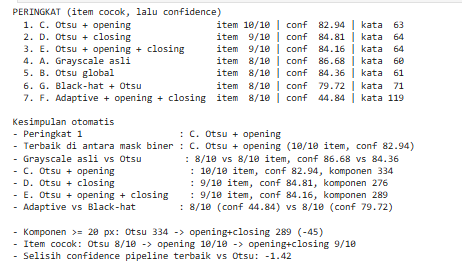

#E.5 — Perbandingan visual sebelum dan sesudah morfologi
Panel berikut memperlihatkan citra asli, mask Otsu mentah (masih berbintik dan bergerigi), serta mask hasil opening + closing yang dipakai sebagai keluaran akhir pipeline.

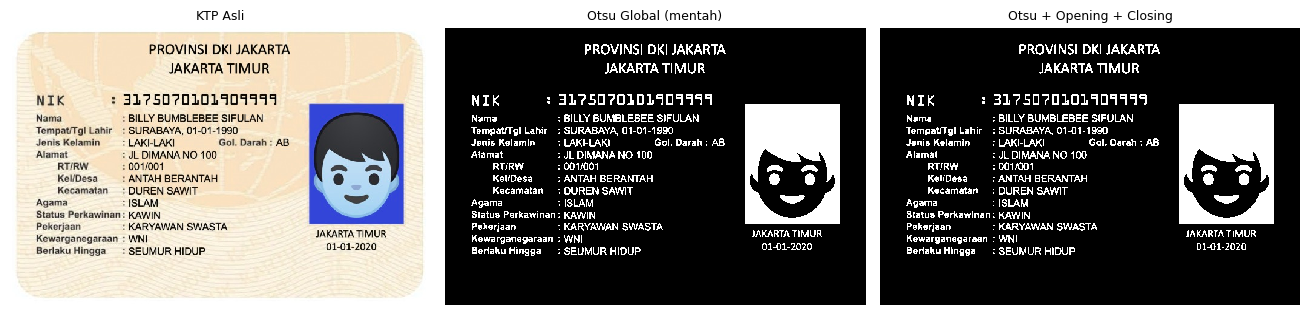

komponen >= 20 px : Otsu 336 -> pipeline 294 (-42)
piksel teks       : Otsu 168013 -> pipeline 168924 (+911)


In [65]:
deret([ktp_rgb, teks_otsu, teks_gabung],
      ['KTP Asli', 'Otsu Global (mentah)', 'Otsu + Opening + Closing'],
      skala=4.4, simpan='21_ktp_pipeline.png')

u_otsu = ukur(teks_otsu, 20)
u_pipe = ukur(teks_gabung, 20)
print('komponen >= 20 px : Otsu %d -> pipeline %d (%+d)'
      % (u_otsu['komponen_besar'], u_pipe['komponen_besar'],
         u_pipe['komponen_besar'] - u_otsu['komponen_besar']))
print('piksel teks       : Otsu %d -> pipeline %d (%+d)'
      % (u_otsu['piksel'], u_pipe['piksel'], u_pipe['piksel'] - u_otsu['piksel']))

#E.6 — Ringkasan seluruh langkah
Tabel berikut dihasilkan otomatis dari metrik yang dikumpulkan sepanjang praktikum.

In [66]:
import pandas as pd

ringkasan = pd.DataFrame(CATATAN)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
display(ringkasan.fillna('-'))

jumlah_berkas = len(list(HASIL.glob('*.png')))
print('Gambar tersimpan di %s : %d berkas' % (HASIL.resolve(), jumlah_berkas))

,Langkah,Keterangan,Piksel awal,Piksel hasil,Komponen,Catatan
0,3,"Dilasi manual, cross 3x3",16375.0,21399,10.0,melebar ke 4 arah sumbu
1,4,"Dilasi OpenCV, square 3x3",16354.0,27429,10.0,sudut ikut melebar
2,5,"Erosi manual, square 5x5",15690.0,6475,6.0,goresan tipis hilang
3,6,"Erosi OpenCV, square 5x5",15690.0,2545,14.0,identik dengan manual
4,7,"Opening manual, k=7",16354.0,11083,6.0,bingkai tipis & teks kecil hilang
5,8,"Closing manual, k=7",16354.0,16873,9.0,celah dan lubang kecil tertutup
6,9a,Dilasi cross 3x3,16354.0,21379,10.0,+1 px per arah sumbu
7,9b,Dilasi cross 5x5,16354.0,26319,10.0,+2 px per arah sumbu
8,10a,Dilasi disk 3x3,16354.0,21379,10.0,sama dengan cross 3x3
9,10b,Dilasi disk 5x5,16354.0,26776,10.0,penebalan isotropik


Gambar tersimpan di /content/hasil_week9 : 25 berkas
